# PISA 2022: 02 Explore, what's going on

Reads the Parquet files made by `01_extract.ipynb` and works through each PISA 2022 file.

**Method (the OECD-prescribed way, not a shortcut):**
- every estimate uses the final student weight `W_FSTUWT`,
- standard errors use the 80 **Fay BRR** replicate weights (`W_FSTURWT1-80`, k = 0.5),
- scores use **all 10 plausible values**, combined with Rubin's rules: total var = sampling var + (1 + 1/10) x imputation var,
- the *OECD average* is the unweighted mean of OECD-country estimates, as in the OECD reports.

Section 0 checks these numbers against the published PISA 2022 results before anything else is trusted.

Set `FOCUS` below to profile any country (3-letter code).

In [1]:
FOCUS = 'ARE'          # country spotlighted in section 15, change freely

from pathlib import Path
import json, re, warnings
import numpy as np, pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt, matplotlib as mpl
warnings.filterwarnings('ignore', category=RuntimeWarning)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'requirements.txt').exists())  # repo root
PQ, OUT = ROOT/'data/parquet', ROOT/'00_pre-project/outputs'
FIG = OUT/'figures'; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_rows', 120,
              'display.float_format', '{:,.2f}'.format)

# palette (dataviz reference instance): categorical slots 1-3, ink, OECD reference in gray
BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
mpl.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': INK2,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'font.size': 9, 'figure.dpi': 110, 'savefig.bbox': 'tight'})

def save(fig, name):
    fig.savefig(FIG/f'{name}.png', dpi=150); plt.show()

DD = pd.read_csv(ROOT/'data/data_dictionary.csv')
# each dataset is a folder of Parquet parts (<90 MB each, so it fits on GitHub); pandas reads a folder like one file
def cols(stem): return pq.ParquetDataset(PQ/f'CY08MSP_{stem}').schema.names
def load(stem, columns): return pd.read_parquet(PQ/f'CY08MSP_{stem}', columns=columns)
def batches(stem, columns, size=50_000):
    # stream a dataset in fixed-size row batches across its parts, in file order
    import pyarrow as pa
    buf = None
    for f in sorted((PQ/f'CY08MSP_{stem}').glob('part-*.parquet')):
        for b in pq.ParquetFile(f).iter_batches(batch_size=size, columns=columns):
            t = pa.Table.from_batches([b])
            buf = t if buf is None else pa.concat_tables([buf, t])
            while buf.num_rows >= size:
                yield buf.slice(0, size); buf = buf.slice(size)
    if buf is not None and buf.num_rows: yield buf

## Estimation engine (BRR + plausible values)

In [2]:
W = ['W_FSTUWT'] + [f'W_FSTURWT{i}' for i in range(1, 81)]
FAY = 1 / (80 * 0.5**2)                      # = 0.05
PV = lambda dom: [f'PV{i}{dom}' for i in range(1, 11)]

def _mean(Y, Wm):
    """weighted means for every (weight, column): (n,81) x (n,P) -> (81,P); NaN-aware per column"""
    M = ~np.isnan(Y)
    return (Wm.T @ np.where(M, Y, 0.0)) / (Wm.T @ M)

def _slope(x, Y, Wm, r2=False):
    """weighted OLS slope of each Y column on x (or R^2), per weight -> (81,P)"""
    Wm = Wm * (~np.isnan(x))[:, None]; x = np.nan_to_num(x)
    sw = Wm.sum(0)[:, None]
    mx, my = (Wm.T @ x)[:, None] / sw, (Wm.T @ Y) / sw
    sxy = (Wm.T @ (x[:, None] * Y)) / sw - mx * my
    sxx = (Wm.T @ (x * x))[:, None] / sw - mx**2
    if not r2: return sxy / sxx
    syy = (Wm.T @ (Y * Y)) / sw - my**2
    return sxy**2 / (sxx * syy)

def _combine(E):
    """E (81,P): row 0 = full weight, rows 1-80 = replicates, columns = plausible values"""
    full = E[0]; P = E.shape[1]
    samp = (FAY * ((E[1:] - full)**2).sum(0)).mean()
    imp = full.var(ddof=1) if P > 1 else 0.0
    return full.mean(), np.sqrt(samp + (1 + 1/P) * imp)

def estimate(df, fn, by='CNT', weights=W):
    out = {}
    for g, d in df.groupby(by, sort=True):
        E = np.asarray(fn(d, d[weights].to_numpy(float)), float)
        out[g] = _combine(E.reshape(81, -1))
    return pd.DataFrame(out, index=['est', 'se']).T

# building blocks
def mean_of(c):  return lambda d, Wm: _mean(d[c].to_numpy(float), Wm)
def pct_of(c, cond):
    def f(d, Wm):
        Y = d[c].to_numpy(float)
        return 100 * _mean(np.where(np.isnan(Y), np.nan, cond(Y).astype(float)), Wm)
    return f
def gap_of(c, grp, a, b):
    def f(d, Wm):
        Y, g = d[c].to_numpy(float), d[grp].to_numpy()
        return _mean(Y, Wm * (g == a)[:, None]) - _mean(Y, Wm * (g == b)[:, None])
    return f
def mean_where(c, grp, val):
    return lambda d, Wm: _mean(d[c].to_numpy(float), Wm * (d[grp].to_numpy() == val)[:, None])
def slope_of(x, c, r2=False):
    return lambda d, Wm: _slope(d[x].to_numpy(float), d[c].to_numpy(float), Wm, r2)

## Load the student file (only the columns used)

In [3]:
IDX = ['ESCS','HISEI','PAREDINT','HOMEPOS','ICTRES','BELONG','BULLIED','FEELSAFE','SCHRISK','RELATST',
       'ANXMAT','MATHEFF','MATHEF21','MATHPERS','GROSAGR','PERSEVAGR','CURIOAGR','STRESAGR','EMOCOAGR',
       'DISCLIM','TEACHSUP','COGACRCO','COGACMCO','EXPOFA','EXPO21ST','FAMSUP','CREATEFF',
       'SDLEFF','PROBSELF','FAMSUPSL','FEELLAH','SCHSUST','LIFESAT','PSYCHSYM','ICTEFFIC','ICTDISTR']
EXTRA = ['ST004D01T','AGE','GRADE','IMMIG','REPEAT','SKIPPING','WORKPAY','EXPECEDU','EFFORT1','EFFORT2',
         'ST273Q06JA','ST273Q07JA','ST347Q01JA','ST350Q01JA','ST356Q01JA','ST255Q01JA']
SUB = ['MCCR','MCQN','MCSS','MCUD','MPEM','MPFS','MPIN','MPRE']
ID = ['CNT','CNTRYID','CNTSCHID','CNTSTUID','OECD','ADMINMODE',
      'Option_CT','Option_FL','Option_ICTQ','Option_WBQ','Option_PQ','Option_TQ']
have = set(cols('STU_QQQ'))
want = ID + W + PV('MATH') + PV('READ') + PV('SCIE') + sum((PV(s) for s in SUB), []) + IDX + EXTRA
missing = [c for c in want if c not in have]
print('not in file:', missing)
stu = load('STU_QQQ', [c for c in want if c in have])
stu['GENDER'] = stu.ST004D01T.map({1: 'F', 2: 'M'})
print(f'{len(stu):,} students x {stu.shape[1]} cols loaded, {stu.memory_usage().sum()/1e9:.2f} GB')

# country names from the SPSS value labels of CNTRYID
lab = json.loads(DD.query("dataset=='student' and variable=='CNTRYID'").value_labels.iloc[0])
cmap = stu[['CNT','CNTRYID']].drop_duplicates().set_index('CNT').CNTRYID
NAME = {c: lab.get(str(float(i)), c) for c, i in cmap.items()}
OECD = sorted(stu.loc[stu.OECD == 1, 'CNT'].unique())
print(f'{stu.CNT.nunique()} countries/economies, {len(OECD)} OECD')

not in file: []


613,744 students x 256 cols loaded, 1.26 GB
80 countries/economies, 37 OECD


In [4]:
def with_oecd(res):
    """append the OECD average row (unweighted mean of country estimates)"""
    r = res.loc[res.index.isin(OECD)]
    return pd.concat([res, pd.DataFrame({'est': [r.est.mean()], 'se': [np.sqrt((r.se**2).sum()) / len(r)]},
                                        index=['OECD'])])

def table(specs, df=None, by='CNT', weights=W):
    """specs: {name: fn} -> wide DataFrame with name and name_se columns, plus OECD average row"""
    df = stu if df is None else df
    parts = {}
    for k, fn in specs.items():
        r = with_oecd(estimate(df, fn, by, weights))
        parts[k], parts[k + '_se'] = r.est, r.se
    t = pd.DataFrame(parts)
    t.insert(0, 'name', [NAME.get(i, 'OECD average') for i in t.index])
    return t

## 0. Validation against the published PISA 2022 results

OECD, *PISA 2022 Results (Volume I)*: OECD average **472 math, 476 reading, 485 science**; Singapore 575 / 543 / 561.
If these don't match to within a point, nothing further down is trustworthy.

In [5]:
scores = table({'math': mean_of(PV('MATH')), 'read': mean_of(PV('READ')), 'sci': mean_of(PV('SCIE'))})
published = {'OECD': (472, 476, 485), 'SGP': (575, 543, 561), 'JPN': (536, 516, 547), 'USA': (465, 504, 499)}
chk = pd.DataFrame({k: dict(zip(['math','read','sci'], v)) for k, v in published.items()}).T
ours = scores.loc[chk.index, ['math','read','sci']].round(0)
display(pd.concat({'published': chk, 'this notebook': ours}, axis=1))
assert (ours - chk).abs().max().max() <= 1, 'estimates do not reproduce the published results'
print('OK: estimates reproduce the OECD published means')

published           this notebook              
          math read  sci          math   read    sci
OECD       472  476  485        472.00 476.00 485.00
SGP        575  543  561        575.00 543.00 561.00
JPN        536  516  547        536.00 516.00 547.00
USA        465  504  499        465.00 504.00 499.00

OK: estimates reproduce the OECD published means


## 1. Who was tested: coverage of every file

In [6]:
def n_by(stem, key='CNT'):
    return load(stem, [key])[key].value_counts()

cov = pd.DataFrame({
    'students':        stu.CNT.value_counts(),
    'schools':         load('SCH_QQQ', ['CNT']).CNT.value_counts(),
    'teachers':        n_by('TCH_QQQ'),
    'creative_think':  n_by('CRT_COG'),
    'fin_literacy':    n_by('FLT_QQQ'),
    'population_15yo': stu.groupby('CNT').W_FSTUWT.sum().round(-3),
}).fillna(0).astype(int)
cov.insert(0, 'name', cov.index.map(NAME)); cov.insert(1, 'OECD', cov.index.isin(OECD))
print(f"{cov.students.sum():,} students in {len(cov)} systems represent ~{cov.population_15yo.sum()/1e6:.1f}M 15-year-olds; "
      f"{cov.schools.sum():,} schools, {cov.teachers.sum():,} teachers")
print('optional modules taken up by:', {c: int((cov[c] > 0).sum()) for c in ['teachers','creative_think','fin_literacy']}, 'systems')
cov.sort_values('students', ascending=False)

613,744 students in 80 systems represent ~28.2M 15-year-olds; 21,629 schools, 68,054 teachers
optional modules taken up by: {'teachers': 18, 'creative_think': 63, 'fin_literacy': 20} systems


,name,OECD,students,schools,teachers,creative_think,fin_literacy,population_15yo
CNT,,,,,,,,
ESP,Spain,True,30800,966,0,30800,3789,459000
ARE,United Arab Emirates,False,24600,840,10092,24600,14604,61000
CAN,Canada,True,23073,863,0,23073,9474,358000
KAZ,Kazakhstan,False,19769,571,0,19769,0,272000
IDN,Indonesia,False,13439,410,0,13439,0,3791000
AUS,Australia,True,13437,743,11397,13437,0,265000
GBR,United Kingdom,True,12972,451,0,0,0,731000
ARG,Argentina,False,12111,457,0,0,0,596000
BRA,Brazil,False,10798,598,5646,10798,6477,2263000


## 2. Headline scores: math, reading, science

,name,math,math_se,read,read_se,sci,sci_se,rank_math
SGP,Singapore,574.70,1.20,542.60,1.90,561.40,1.30,1
MAC,Macao (China),551.90,1.10,510.40,1.30,543.10,1.10,2
TAP,Chinese Taipei,547.10,3.80,515.20,3.30,537.40,3.30,3
HKG,Hong Kong (China),540.40,3.00,499.70,2.80,520.40,2.80,4
JPN,Japan,535.60,2.90,515.90,3.20,546.60,2.80,5
KOR,Korea,527.30,3.90,515.40,3.60,527.80,3.60,6
EST,Estonia,509.90,2.00,511.00,2.40,525.80,2.10,7
CHE,Switzerland,508.00,2.10,483.30,2.30,502.50,2.20,8
CAN,Canada,496.90,1.60,507.10,2.00,515.00,1.90,9
NLD,Netherlands,492.70,3.80,459.20,4.30,488.30,4.10,10


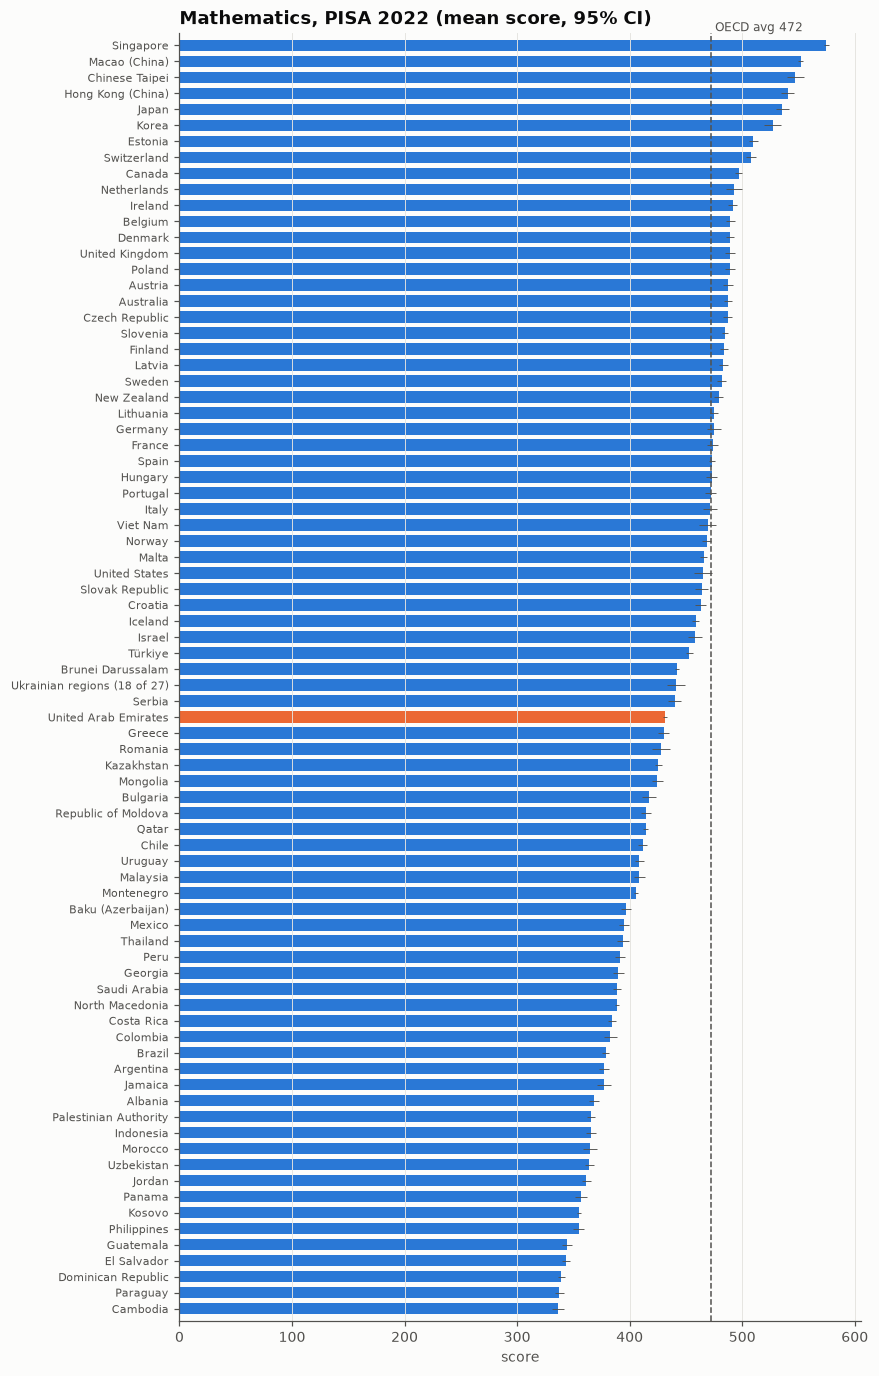

In [7]:
scores = scores.sort_values('math', ascending=False)
scores['rank_math'] = scores.drop('OECD').math.rank(ascending=False).astype('Int64')
display(scores[['name','math','math_se','read','read_se','sci','sci_se','rank_math']].round(1))

def rank_chart(t, col, title, xlabel, name, oecd_val=None):
    t = t.drop('OECD', errors='ignore').sort_values(col)
    fig, ax = plt.subplots(figsize=(8, max(4, .19 * len(t))))
    ax.barh(t.name, t[col], color=[ORANGE if i == FOCUS else BLUE for i in t.index], height=.72)
    if col + '_se' in t:
        ax.errorbar(t[col], t.name, xerr=1.96 * t[col + '_se'], fmt='none', ecolor=INK2, lw=.6)
    if oecd_val is not None:
        ax.axvline(oecd_val, color=INK2, ls='--', lw=1)
        ax.text(oecd_val, len(t) - .3, f' OECD avg {oecd_val:.0f}', color=INK2, va='bottom', fontsize=8)
    ax.set_title(title, loc='left'); ax.set_xlabel(xlabel); ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', labelsize=7); ax.margins(y=.005)
    save(fig, name)

rank_chart(scores, 'math', 'Mathematics, PISA 2022 (mean score, 95% CI)', 'score', '02_math_rank',
           scores.loc['OECD', 'math'])

between-country correlation of domain means:


,math,read,sci
math,1.00,0.94,0.98
read,0.94,1.00,0.98
sci,0.98,0.98,1.00


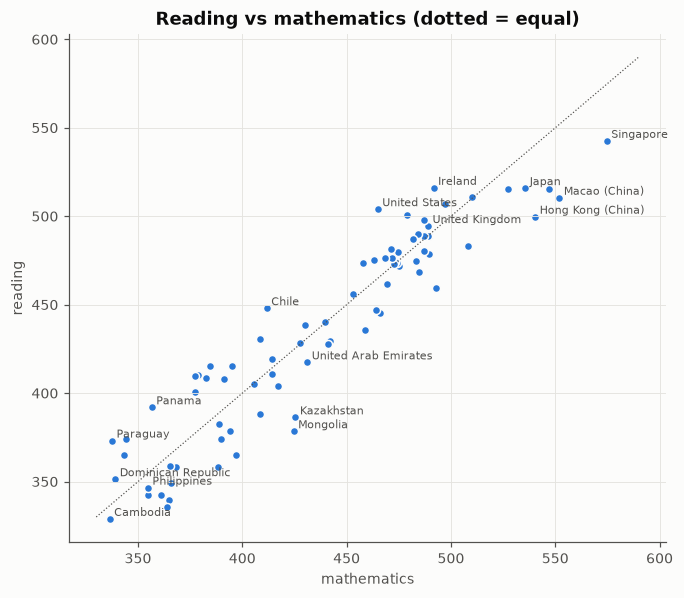

In [8]:
# how different are the three domains? correlation across countries + read-vs-math scatter
c = scores.drop('OECD')
print('between-country correlation of domain means:'); display(c[['math','read','sci']].corr().round(3))
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(c.math, c.read, s=28, color=BLUE, edgecolor=SURF, lw=1)
ax.plot([330, 590], [330, 590], color=INK2, lw=.8, ls=':')
for i in c.index:
    if i in ('SGP','IRL','USA','GBR','JPN','KHM','DOM','PHL', FOCUS) or abs(c.math[i] - c.read[i]) > 35:
        ax.annotate(c.name[i], (c.math[i], c.read[i]), fontsize=7, xytext=(3, 2), textcoords='offset points', color=INK2)
ax.set(xlabel='mathematics', ylabel='reading', title='Reading vs mathematics (dotted = equal)')
save(fig, '02_read_vs_math')

## 3. Proficiency levels: low performers and top performers

In [9]:
# Level-2 and Level-5 lower bounds on each PISA scale (PISA 2022 Technical Report)
CUT = {'MATH': (420.07, 606.99), 'READ': (407.47, 625.61), 'SCIE': (409.54, 633.33)}
prof = table({f'low_{d}': pct_of(PV(d), lambda y, c=c: y < c[0]) for d, c in CUT.items()} |
             {f'top_{d}': pct_of(PV(d), lambda y, c=c: y >= c[1]) for d, c in CUT.items()})
prof = prof.sort_values('low_MATH')
display(prof[['name','low_MATH','top_MATH','low_READ','top_READ','low_SCIE','top_SCIE']].round(1))

# the full math level distribution per country
MLV = [-np.inf, 233.17, 295.47, 357.77, 420.07, 482.38, 544.68, 606.99, 669.30, np.inf]
LVN = ['<1c','1c','1b','1a','2','3','4','5','6']
lev = table({L: pct_of(PV('MATH'), lambda y, a=a, b=b: (y >= a) & (y < b))
             for L, a, b in zip(LVN, MLV[:-1], MLV[1:])})[['name'] + LVN]
lev.round(1).sort_values('2')

,name,low_MATH,top_MATH,low_READ,top_READ,low_SCIE,top_SCIE
SGP,Singapore,8.00,40.50,11.20,22.60,7.80,24.40
MAC,Macao (China),8.40,28.60,12.60,8.90,7.40,14.70
JPN,Japan,12.00,23.00,13.80,12.30,8.00,18.00
HKG,Hong Kong (China),13.80,27.20,17.50,9.00,12.80,10.70
TAP,Chinese Taipei,14.60,31.70,15.80,14.00,12.10,17.80
EST,Estonia,15.00,13.10,13.80,10.60,10.10,11.60
KOR,Korea,16.20,22.90,14.70,13.30,13.70,15.70
IRL,Ireland,19.00,7.20,11.40,10.30,15.60,7.50
CHE,Switzerland,19.50,16.10,24.60,8.60,19.20,9.60
DNK,Denmark,20.40,7.70,19.00,6.30,19.50,7.00


,name,<1c,1c,1b,1a,2,3,4,5,6
DOM,Dominican Republic,1.50,19.50,45.10,26.40,6.70,0.80,0.10,0.00,0.00
SLV,El Salvador,1.90,19.00,42.00,26.50,8.80,1.70,0.20,0.00,0.00
KHM,Cambodia,7.60,20.60,33.70,26.10,9.50,2.20,0.30,0.00,0.00
GTM,Guatemala,5.10,18.30,35.20,28.20,10.50,2.30,0.30,0.00,0.00
PRY,Paraguay,8.30,22.20,30.70,24.30,11.00,3.00,0.60,0.00,0.00
SGP,Singapore,0.00,0.30,1.90,5.90,11.20,17.60,22.60,22.00,18.60
KSV,Kosovo,1.40,15.10,38.90,29.60,11.70,2.90,0.30,0.00,0.00
PAN,Panama,1.60,15.40,37.10,29.70,12.10,3.30,0.70,0.00,0.00
PHL,Philippines,1.10,16.70,38.60,27.70,12.20,3.20,0.50,0.10,0.00
TAP,Chinese Taipei,0.20,0.90,4.30,9.20,13.50,18.70,21.50,18.00,13.70


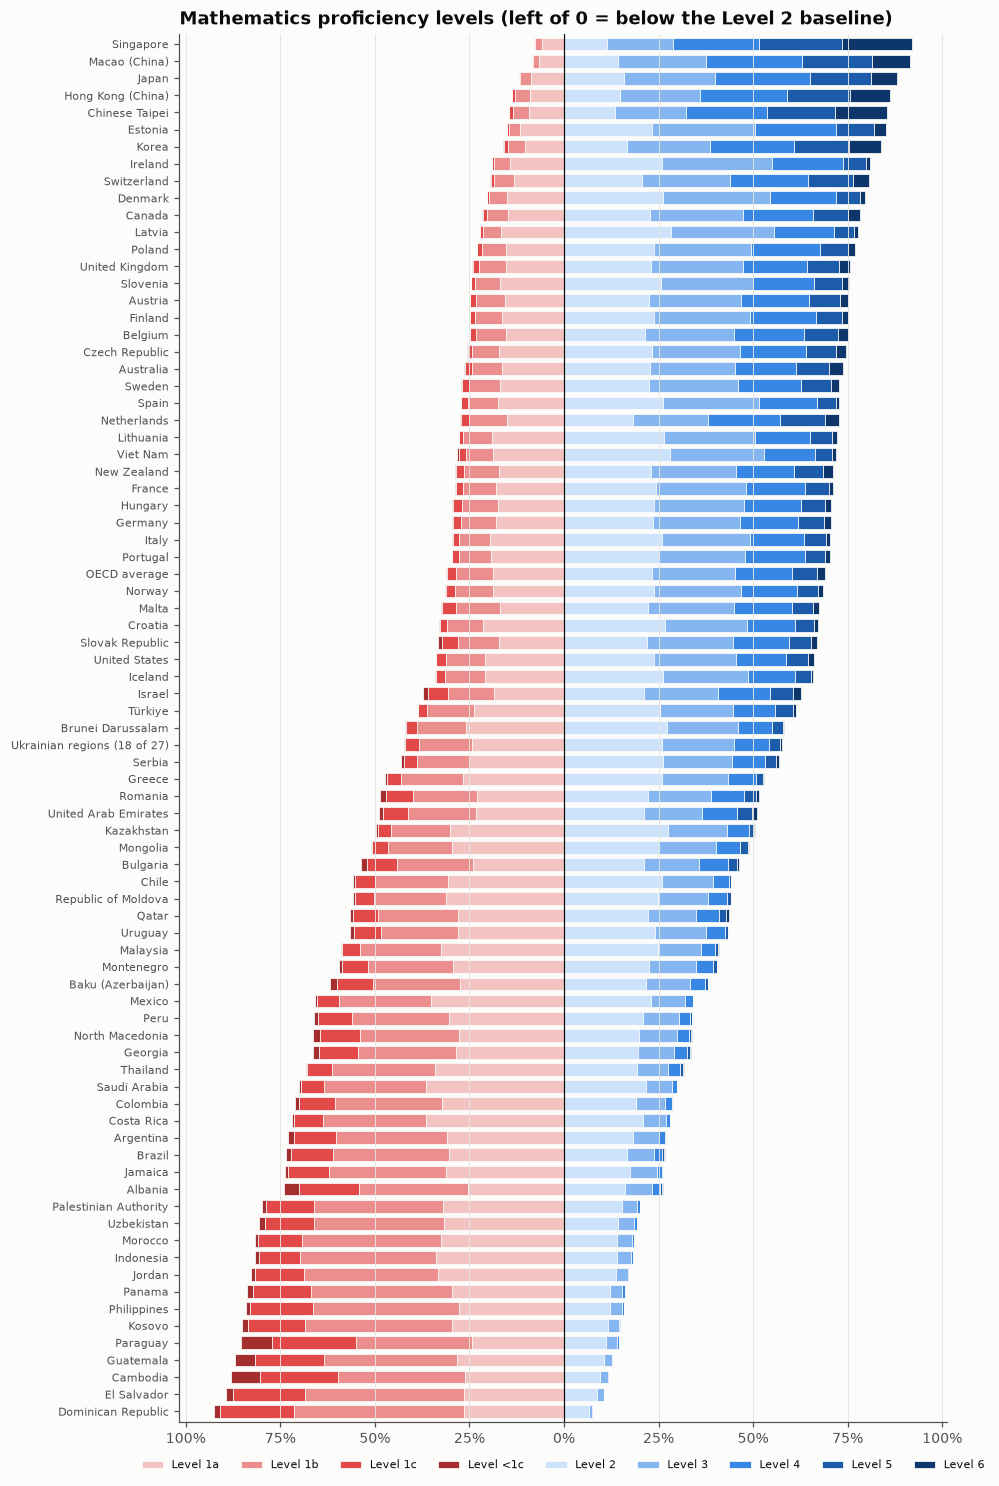

In [10]:
# diverging stacked bar: below Level 2 to the left, Level 2+ to the right
t = lev.sort_values(['<1c','1c','1b','1a'], ascending=True).copy()
t = t.assign(below=t[['<1c','1c','1b','1a']].sum(axis=1)).sort_values('below', ascending=False)
blues = ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b']        # levels 2..6
reds  = ['#f3c3c2', '#ea8f8e', '#e34948', '#a52f2e']                   # 1a..<1c going outward
fig, ax = plt.subplots(figsize=(9, .19 * len(t) + 1))
left = np.zeros(len(t))
for L, col in zip(['1a','1b','1c','<1c'], reds):
    ax.barh(t.name, -t[L], left=-left, color=col, height=.75, label=f'Level {L}', edgecolor=SURF, lw=.5)
    left += t[L].to_numpy()
right = np.zeros(len(t))
for L, col in zip(['2','3','4','5','6'], blues):
    ax.barh(t.name, t[L], left=right, color=col, height=.75, label=f'Level {L}', edgecolor=SURF, lw=.5)
    right += t[L].to_numpy()
ax.axvline(0, color=INK, lw=.8); ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=7)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{abs(v):.0f}%'))
ax.set_title('Mathematics proficiency levels (left of 0 = below the Level 2 baseline)', loc='left')
ax.legend(ncol=9, fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.02), frameon=False)
ax.margins(y=.003); save(fig, '03_math_levels')

## 4. Mathematics sub-scales: where each system is relatively strong or weak

Content (MCCR change & relationships, MCQN quantity, MCSS space & shape, MCUD uncertainty & data)
and process (MPEM employ, MPFS formulate, MPIN interpret, MPRE reason) sub-scales, as a difference from the country's overall math mean.

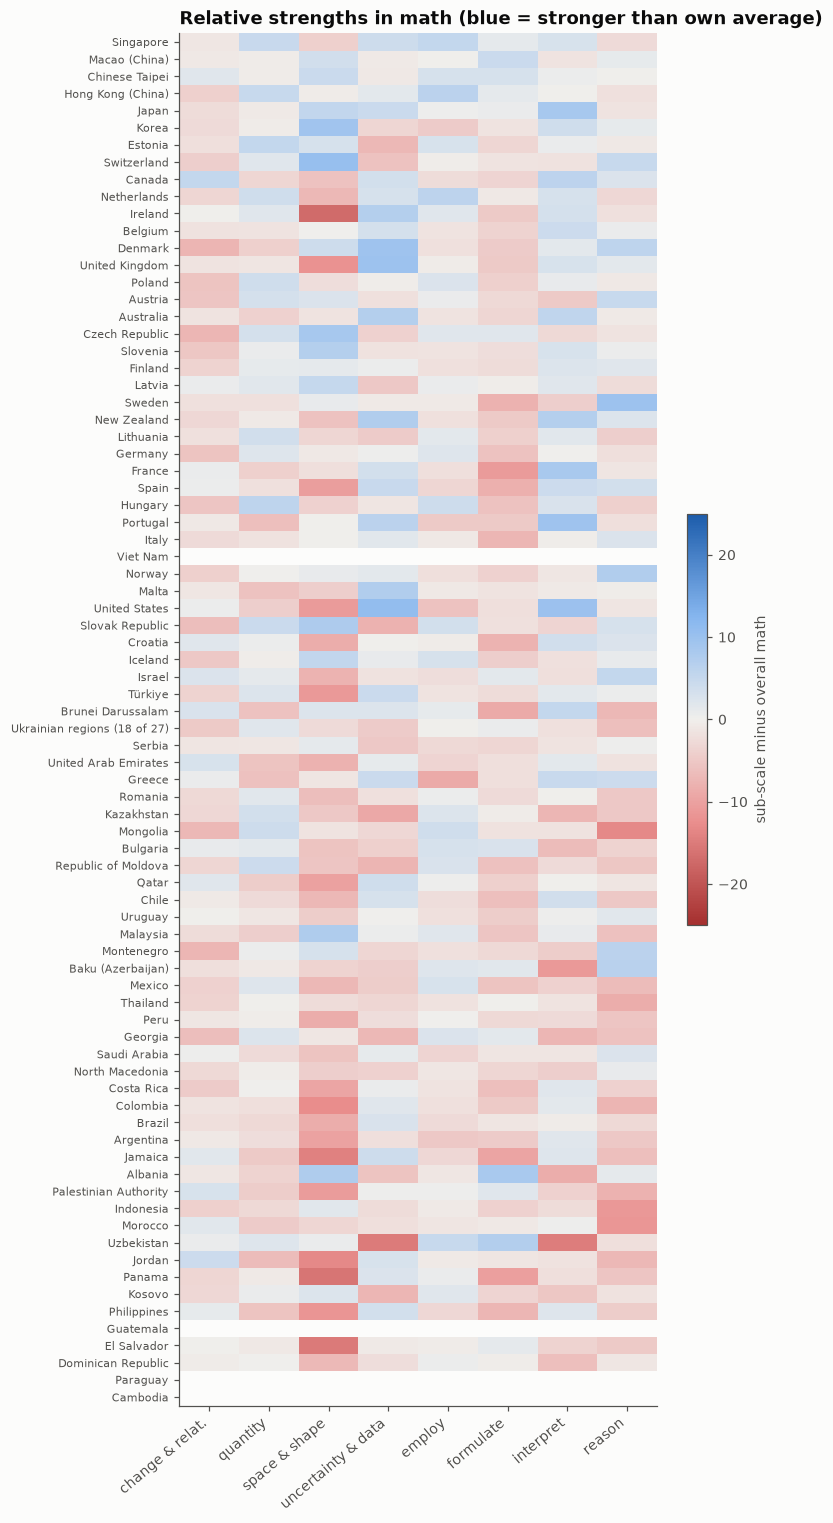

In [11]:
subs = table({s: (lambda d, Wm, s=s: _mean(d[PV(s)].to_numpy(float), Wm) - _mean(d[PV('MATH')].to_numpy(float), Wm))
              for s in SUB})
LAB = {'MCCR':'change & relat.','MCQN':'quantity','MCSS':'space & shape','MCUD':'uncertainty & data',
       'MPEM':'employ','MPFS':'formulate','MPIN':'interpret','MPRE':'reason'}
h = subs.set_index('name')[SUB].rename(columns=LAB).loc[lambda x: x.index != 'OECD average']
h = h.loc[scores.drop('OECD').name]          # order by overall math
fig, ax = plt.subplots(figsize=(7, .19 * len(h) + 1))
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
div = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ea8f8e', '#a52f2e'])
im = ax.imshow(h.to_numpy(), cmap=div.reversed(), norm=TwoSlopeNorm(0, -25, 25), aspect='auto')
ax.set_xticks(range(len(h.columns)), h.columns, rotation=40, ha='right'); ax.set_yticks(range(len(h)), h.index, fontsize=7)
ax.grid(False); plt.colorbar(im, ax=ax, shrink=.3, label='sub-scale minus overall math')
ax.set_title('Relative strengths in math (blue = stronger than own average)', loc='left')
save(fig, '04_math_subscales')

## 5. Gender gaps (boys minus girls)

,name,gap_MATH,gap_MATH_se,gap_READ,gap_READ_se,gap_SCIE,gap_SCIE_se
ALB,Albania,-19.10,2.80,-40.10,2.80,-28.50,2.90
PSE,Palestinian Authority,-15.60,3.40,-49.40,3.60,-29.60,3.80
JOR,Jordan,-15.00,4.20,-46.10,4.70,-32.90,4.90
PHL,Philippines,-14.20,1.90,-34.60,2.60,-14.70,3.10
JAM,Jamaica,-13.50,5.00,-35.20,6.90,-20.00,6.50
BRN,Brunei Darussalam,-11.30,1.60,-33.90,2.00,-12.20,2.40
MYS,Malaysia,-10.50,2.00,-31.00,2.40,-13.40,2.30
QAT,Qatar,-7.90,2.20,-40.20,3.40,-21.30,2.60
ARE,United Arab Emirates,-7.10,1.70,-44.50,2.00,-17.10,2.00
QAZ,Baku (Azerbaijan),-7.10,2.50,-37.50,2.20,-12.40,2.30


OECD average: boys +9.1 in math, -24.2 in reading, -0.0 in science
math gap significant  (+1 boys ahead, -1 girls ahead, 0 n.s.): {1.0: 40, -0.0: 24, -1.0: 16}
reading gap significant: {-1.0: 78, -0.0: 2}


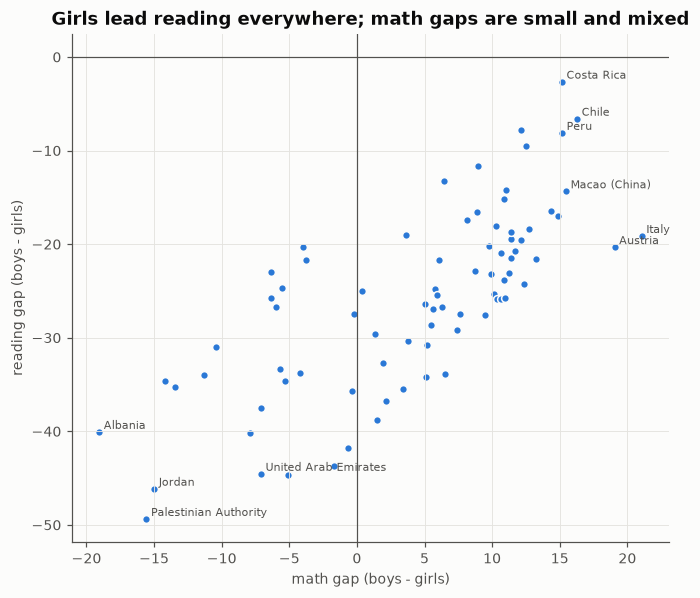

In [12]:
gg = table({f'gap_{d}': gap_of(PV(d), 'GENDER', 'M', 'F') for d in ['MATH','READ','SCIE']})
gg = gg.sort_values('gap_MATH')
display(gg.round(1))
o = gg.loc['OECD']
print(f"OECD average: boys {o.gap_MATH:+.1f} in math, {o.gap_READ:+.1f} in reading, {o.gap_SCIE:+.1f} in science")
sig = lambda k: ((gg.drop('OECD')[k].abs() > 1.96 * gg.drop('OECD')[k + '_se']) * np.sign(gg.drop('OECD')[k])).value_counts()
print('math gap significant  (+1 boys ahead, -1 girls ahead, 0 n.s.):', sig('gap_MATH').to_dict())
print('reading gap significant:', sig('gap_READ').to_dict())

fig, ax = plt.subplots(figsize=(7, 6))
t = gg.drop('OECD')
ax.axhline(0, color=INK2, lw=.8); ax.axvline(0, color=INK2, lw=.8)
ax.scatter(t.gap_MATH, t.gap_READ, s=26, color=BLUE, edgecolor=SURF)
for i in t.index:
    if abs(t.gap_MATH[i]) > 15 or t.gap_READ[i] < -45 or i == FOCUS:
        ax.annotate(t.name[i], (t.gap_MATH[i], t.gap_READ[i]), fontsize=7, xytext=(3, 2), textcoords='offset points', color=INK2)
ax.set(xlabel='math gap (boys - girls)', ylabel='reading gap (boys - girls)',
       title='Girls lead reading everywhere; math gaps are small and mixed')
save(fig, '05_gender')

## 6. Equity: how much does socio-economic status (ESCS) predict math?

- **gradient**: score points per 1-unit ESCS increase (within country),
- **strength**: % of math variance explained by ESCS,
- math gap between top- and bottom-quarter ESCS students in each country.

systems without ESCS: ['Costa Rica']


,name,escs_mean,escs_mean_se,gradient,gradient_se,pct_var,pct_var_se,q4_minus_q1,q4_minus_q1_se,math
KHM,Cambodia,-2.01,0.03,8.13,2.17,1.92,1.02,20.97,6.79,336.40
UZB,Uzbekistan,-0.69,0.02,9.48,1.19,2.01,0.49,22.40,3.44,363.94
KAZ,Kazakhstan,-0.37,0.02,18.73,1.29,3.94,0.52,41.33,2.97,425.44
ALB,Albania,-0.75,0.02,16.68,1.69,4.48,0.86,48.72,4.71,368.22
PHL,Philippines,-1.34,0.04,12.50,1.84,4.77,1.28,36.48,5.19,354.72
MAC,Macao (China),-0.45,0.01,22.67,1.58,4.96,0.67,55.08,4.11,551.92
QAZ,Baku (Azerbaijan),-0.51,0.03,20.82,1.78,5.21,0.85,54.00,4.38,396.88
JOR,Jordan,-0.82,0.02,12.91,1.30,5.24,1.00,39.88,3.57,361.23
IDN,Indonesia,-1.56,0.04,13.74,1.68,5.51,1.33,34.09,4.62,365.53
KSV,Kosovo,-0.34,0.01,16.77,1.09,5.68,0.72,39.10,2.92,354.96


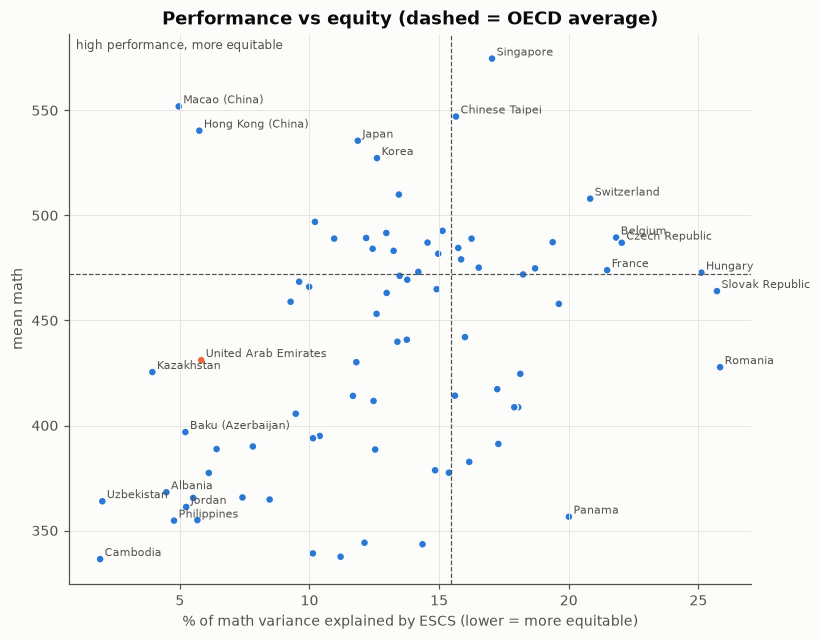

In [13]:
def wquartile(d):
    # weighted within-country ESCS quartile (NaN where ESCS missing; all-NaN if a country has no ESCS)
    d = d[['ESCS', 'W_FSTUWT']].dropna().sort_values('ESCS')
    share = d.W_FSTUWT.cumsum() / d.W_FSTUWT.sum()
    return np.minimum(np.ceil(share * 4), 4)
stu['ESCS_Q'] = pd.concat([wquartile(d) for _, d in stu.groupby('CNT')]).reindex(stu.index)
print('systems without ESCS:', [NAME[c] for c, v in stu.groupby('CNT').ESCS.count().items() if v == 0])
eq = table({'escs_mean': mean_of(['ESCS']),
            'gradient':  slope_of('ESCS', PV('MATH')),
            'pct_var':   lambda d, Wm: 100 * _slope(d.ESCS.to_numpy(float), d[PV('MATH')].to_numpy(float), Wm, r2=True),
            'q4_minus_q1': gap_of(PV('MATH'), 'ESCS_Q', 4.0, 1.0)})
eq = eq.join(scores[['math']])
display(eq.sort_values('pct_var').round(2))

t = eq.drop('OECD'); o = eq.loc['OECD']
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.axvline(o.pct_var, color=INK2, ls='--', lw=.8); ax.axhline(o.math, color=INK2, ls='--', lw=.8)
ax.scatter(t.pct_var, t.math, s=28, color=[ORANGE if i == FOCUS else BLUE for i in t.index], edgecolor=SURF)
for i in t.index:
    if t.math[i] > 520 or t.pct_var[i] > 20 or t.pct_var[i] < 5.5 and i != 'KSV' or i == FOCUS:
        ax.annotate(t.name[i], (t.pct_var[i], t.math[i]), fontsize=7, xytext=(3, 2), textcoords='offset points', color=INK2)
ax.set(xlabel='% of math variance explained by ESCS (lower = more equitable)', ylabel='mean math',
       title='Performance vs equity (dashed = OECD average)')
ax.text(.01, .99, 'high performance, more equitable', transform=ax.transAxes, va='top', color=INK2, fontsize=8)
save(fig, '06_equity')

## 7. What's associated with math *within* countries

For each index: the within-country change in math per 1 SD of the index (indices are standardised to OECD SD = 1),
estimated per country with BRR and averaged over OECD countries. These are **associations**, not causal effects,
and many indices are correlated with ESCS.

,label,per_SD,se,countries_positive,coverage
ANXMAT,Mathematics Anxiety (WLE),-23.01,0.24,0,0.78
FAMSUPSL,Family support for self-directed learning (WLE),-13.14,0.28,4,0.58
SCHRISK,School safety risks (WLE),-11.57,0.25,0,0.76
PROBSELF,Problems with self-directed learning (WLE),-10.88,0.28,1,0.59
ICTDISTR,Distress from online content and cyberbullying,-8.92,0.26,16,0.43
BULLIED,Being bullied (WLE),-8.05,0.25,4,0.93
COGACMCO,Cognitive activation in mathematics: Encourage...,-3.67,0.27,25,0.81
EXPO21ST,Exposure to Mathematical Reasoning and 21st ce...,-0.81,0.28,33,0.83
FAMSUP,Family support (WLE),1.92,0.27,65,0.77
FEELLAH,Feelings about learning at home (WLE),2.75,0.31,38,0.38


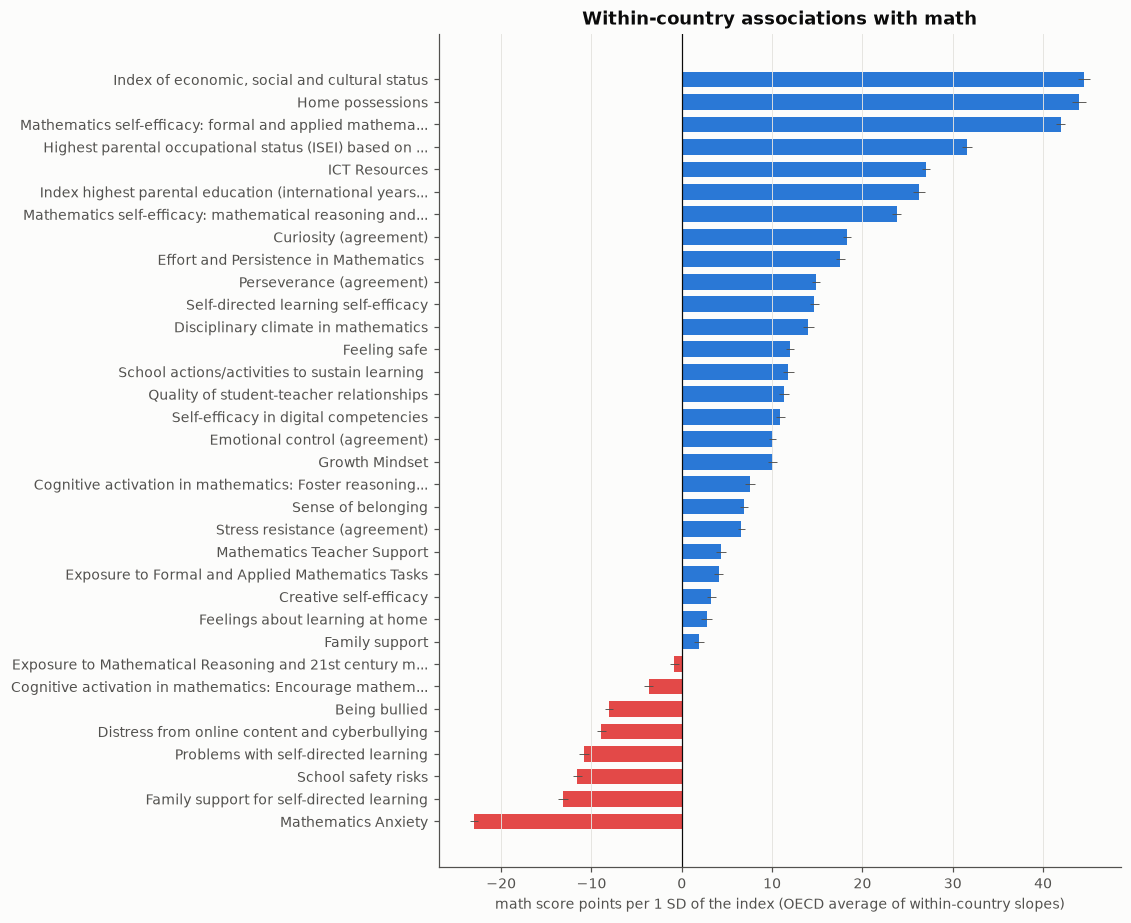

In [14]:
assoc = {}
for v in IDX:
    if v not in stu or stu[v].notna().mean() < .2: continue
    r = with_oecd(estimate(stu, slope_of(v, PV('MATH'))))
    sd = stu[v].std()
    assoc[v] = dict(label=DD.query('dataset=="student" and variable==@v').label.iloc[0],
                    per_SD=r.loc['OECD','est'] * sd, se=r.loc['OECD','se'] * sd,
                    countries_positive=int((r.drop('OECD').est > 0).sum()), coverage=round(stu[v].notna().mean(), 2))
assoc = pd.DataFrame(assoc).T.astype({'per_SD': float, 'se': float}).sort_values('per_SD')
display(assoc.round(2))

fig, ax = plt.subplots(figsize=(8, .26 * len(assoc) + 1))
ax.barh(assoc.label.str.replace(r' \(WLE\)', '', regex=True).map(lambda x: x if len(x) <= 55 else x[:53] + '...'), assoc.per_SD,
        color=[BLUE if v > 0 else RED for v in assoc.per_SD], height=.7)
ax.errorbar(assoc.per_SD, range(len(assoc)), xerr=1.96 * assoc.se, fmt='none', ecolor=INK2, lw=.6)
ax.axvline(0, color=INK, lw=.8); ax.grid(axis='y', visible=False)
ax.set(xlabel='math score points per 1 SD of the index (OECD average of within-country slopes)',
       title='Within-country associations with math')
save(fig, '07_associations')

## 8. Phones and distraction in math lessons

,name,pct_distracted_own,pct_distracted_own_se,pct_distracted_others,pct_distracted_others_se,math
JPN,Japan,5.20,0.50,3.90,0.40,535.60
KOR,Korea,9.40,0.60,8.80,0.50,527.30
BRN,Brunei Darussalam,11.50,0.40,10.50,0.40,442.10
MAC,Macao (China),13.30,0.60,11.60,0.50,551.90
GTM,Guatemala,14.20,0.60,12.50,0.60,344.20
VNM,Viet Nam,14.30,0.70,12.70,0.70,469.40
TAP,Chinese Taipei,15.90,1.00,12.50,0.70,547.10
HKG,Hong Kong (China),16.40,0.90,15.30,0.90,540.40
MLT,Malta,16.40,0.80,16.10,0.70,466.00
GBR,United Kingdom,18.60,0.90,20.40,0.80,489.00


OECD average math by how often students are distracted by digital devices in math class:
every lesson         455.40
most lessons         471.90
some lessons         478.70
never/almost never   484.30


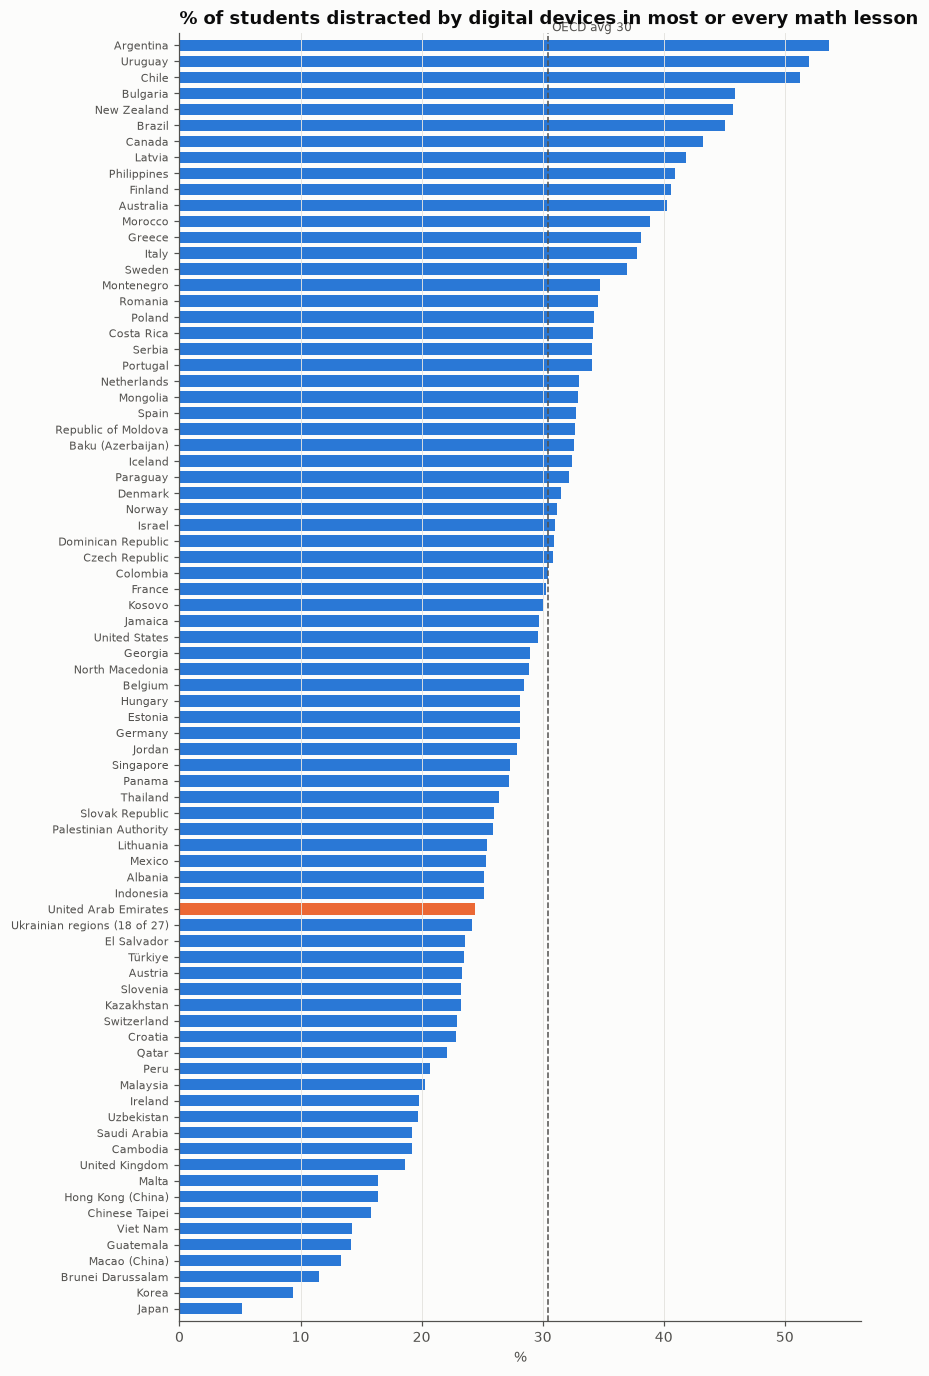

In [15]:
dist = table({'pct_distracted_own':    pct_of(['ST273Q06JA'], lambda y: y <= 2),
              'pct_distracted_others': pct_of(['ST273Q07JA'], lambda y: y <= 2)}).join(scores[['math']])
dist = dist.sort_values('pct_distracted_own')
display(dist.round(1))
FREQ = {1: 'every lesson', 2: 'most lessons', 3: 'some lessons', 4: 'never/almost never'}
by_freq = pd.Series({lab: with_oecd(estimate(stu, mean_where(PV('MATH'), 'ST273Q06JA', float(k)))).loc['OECD', 'est']
                     for k, lab in FREQ.items()})
print('OECD average math by how often students are distracted by digital devices in math class:')
print(by_freq.round(1).to_string())
rank_chart(dist.rename(columns={'pct_distracted_own': 'v'}), 'v',
           '% of students distracted by digital devices in most or every math lesson', '%',
           '08_distraction', dist.loc['OECD', 'pct_distracted_own'])

## 9. COVID-19 school closures

,name,closed_gt3m,closed_gt3m_se,closed_any,closed_any_se,learnt_less,learnt_less_se,feel_prepared_next_time,feel_prepared_next_time_se,SDLEFF,SDLEFF_se,PROBSELF,PROBSELF_se,math
TAP,Chinese Taipei,9.80,0.50,62.00,1.00,51.80,1.00,47.80,1.10,-0.20,0.00,-0.60,0.00,547.10
ISL,Iceland,11.10,0.70,75.20,0.90,53.20,1.20,72.70,1.20,0.10,0.00,-0.40,0.00,458.90
SWE,Sweden,14.60,0.70,72.00,1.40,57.00,1.00,67.20,0.90,0.10,0.00,-0.10,0.00,481.80
JPN,Japan,15.50,0.70,71.30,0.60,60.10,0.80,30.90,0.90,-0.70,0.00,-0.60,0.00,535.60
KOR,Korea,20.80,0.80,68.00,0.80,76.30,1.10,53.40,1.00,-0.20,0.00,-0.40,0.00,527.30
CHE,Switzerland,23.50,0.70,84.80,0.60,62.10,1.00,74.60,0.90,0.20,0.00,-0.20,0.00,508.00
HRV,Croatia,29.70,0.80,82.80,0.70,66.10,0.90,77.00,0.80,0.30,0.00,-0.00,0.00,463.10
FIN,Finland,31.20,0.70,88.40,0.40,41.00,0.70,73.90,0.70,0.20,0.00,-0.20,0.00,484.10
SRB,Serbia,31.50,0.70,78.90,0.60,64.50,1.00,55.60,0.90,-0.20,0.00,0.10,0.00,439.90
LTU,Lithuania,33.20,0.70,74.60,0.70,56.30,0.90,69.10,0.80,0.20,0.00,-0.10,0.00,475.10


between-country correlation, % closed >3 months vs mean math: -0.33


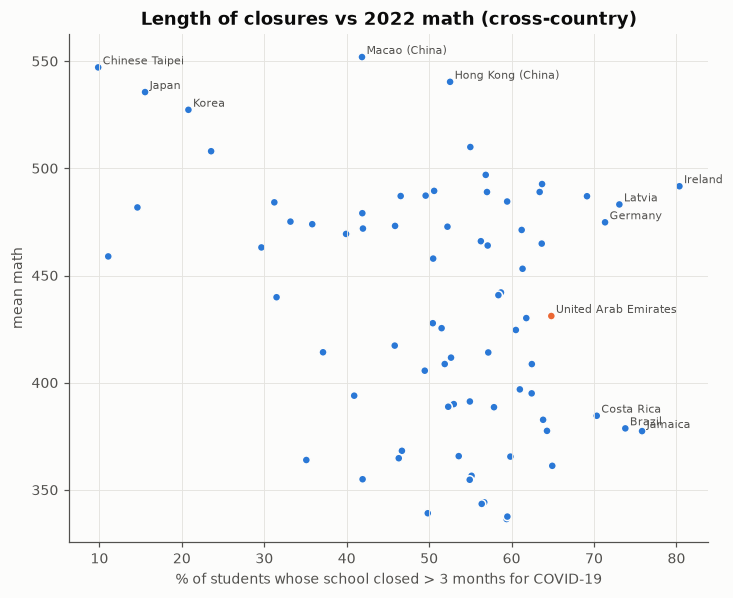

In [16]:
cov19 = table({'closed_gt3m':  pct_of(['ST347Q01JA'], lambda y: y >= 4),
               'closed_any':   pct_of(['ST347Q01JA'], lambda y: y >= 2),
               'learnt_less':  pct_of(['ST350Q01JA'], lambda y: y == 1),
               'feel_prepared_next_time': pct_of(['ST356Q01JA'], lambda y: y >= 3),
               'SDLEFF': mean_of(['SDLEFF']), 'PROBSELF': mean_of(['PROBSELF'])}).join(scores[['math']])
display(cov19.sort_values('closed_gt3m').round(1))
t = cov19.drop('OECD').dropna(subset=['closed_gt3m'])
print('between-country correlation, % closed >3 months vs mean math:', round(t.closed_gt3m.corr(t.math), 2))
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(t.closed_gt3m, t.math, s=28, color=[ORANGE if i == FOCUS else BLUE for i in t.index], edgecolor=SURF)
for i in t.index:
    if t.closed_gt3m[i] > 70 or t.closed_gt3m[i] < 10 or t.math[i] > 520 or i == FOCUS:
        ax.annotate(t.name[i], (t.closed_gt3m[i], t.math[i]), fontsize=7, xytext=(3, 2), textcoords='offset points', color=INK2)
ax.set(xlabel='% of students whose school closed > 3 months for COVID-19', ylabel='mean math',
       title='Length of closures vs 2022 math (cross-country)')
save(fig, '09_covid')

## 10. Schools: type, resources, and how much schools differ

In [17]:
SCHV = ['CNTSCHID','SCHLTYPE','STRATIO','SCHSIZE','CLSIZE','EDUSHORT','STAFFSHORT','STUBEHA','TEACHBEHA',
        'SCHAUTO','DIGDVPOL','SCHSEL','ABGMATH']
sch = load('SCH_QQQ', [c for c in SCHV if c in cols('SCH_QQQ')])
s = stu.merge(sch, on='CNTSCHID', how='left')
print(f'students matched to a school record: {s.SCHLTYPE.notna().mean():.1%}')
s['PRIVATE'] = s.SCHLTYPE.map({1: 1.0, 2: 1.0, 3: 0.0})
schools = table({'pct_private':   pct_of(['PRIVATE'], lambda y: y == 1),
                 'private_minus_public': gap_of(PV('MATH'), 'PRIVATE', 1.0, 0.0),
                 'stratio':       mean_of(['STRATIO']),
                 'class_size':    mean_of(['CLSIZE']),
                 'edu_shortage':  mean_of(['EDUSHORT']),
                 'staff_shortage': mean_of(['STAFFSHORT'])}, df=s)

# descriptive between-school share of math variance (weighted, per PV, averaged), not a multilevel model
def between_share(d):
    out = []
    for p in PV('MATH'):
        w, y = d.W_FSTUWT.to_numpy(), d[p].to_numpy()
        mu = np.average(y, weights=w)
        sm = d.assign(wy=w * y).groupby('CNTSCHID').agg(wy=('wy', 'sum'), w=('W_FSTUWT', 'sum'))
        between = (sm.w * (sm.wy / sm.w - mu)**2).sum() / w.sum()
        out.append(between / np.average((y - mu)**2, weights=w))
    return 100 * np.mean(out)
schools['between_school_pct'] = s.groupby('CNT').apply(between_share)
schools.loc['OECD', 'between_school_pct'] = schools.loc[OECD, 'between_school_pct'].mean()
schools = schools.join(scores[['math']])
display(schools[['name','pct_private','private_minus_public','private_minus_public_se','stratio','class_size',
                 'edu_shortage','staff_shortage','between_school_pct','math']].sort_values('between_school_pct').round(1))

students matched to a school record: 92.6%


,name,pct_private,private_minus_public,private_minus_public_se,stratio,class_size,edu_shortage,staff_shortage,between_school_pct,math
FIN,Finland,4.70,30.70,8.20,10.90,19.90,-0.60,0.20,11.60,484.10
ISL,Iceland,1.60,21.30,15.40,10.80,20.30,-0.50,-0.10,11.80,458.90
NOR,Norway,NaN,NaN,NaN,NaN,NaN,0.10,0.20,13.70,468.40
IRL,Ireland,NaN,NaN,NaN,12.40,24.70,-0.70,0.10,14.30,491.60
SAU,Saudi Arabia,17.20,25.70,5.30,11.80,32.90,0.20,0.80,16.10,388.80
DNK,Denmark,22.30,20.70,5.50,12.40,21.80,-0.80,-0.50,16.90,489.30
QAZ,Baku (Azerbaijan),0.50,32.80,8.20,16.70,29.00,0.30,0.50,17.60,396.90
ESP,Spain,30.70,35.30,3.30,11.60,26.10,-0.30,-0.10,19.60,473.10
MLT,Malta,43.60,47.80,3.30,6.50,19.80,-0.50,0.10,19.60,466.00
SWE,Sweden,20.10,25.70,6.20,12.10,24.20,-0.60,0.50,19.80,481.80


In [18]:
# does the private-school advantage survive once you account for who attends? (OECD average)
def adj_gap(d, Wm):
    """private-public math gap controlling for student ESCS and school mean ESCS, per weight x PV"""
    d = d.dropna(subset=['PRIVATE', 'ESCS'])
    if d.PRIVATE.nunique() < 2 or len(d) < 200: return np.full((81, 10), np.nan)
    Wm = d[W].to_numpy(float)
    X = np.column_stack([np.ones(len(d)), d.PRIVATE, d.ESCS, d.groupby('CNTSCHID').ESCS.transform('mean')])
    Y = d[PV('MATH')].to_numpy(float)
    return np.array([np.linalg.lstsq(X * np.sqrt(w)[:, None], Y * np.sqrt(w)[:, None], rcond=None)[0][1] for w in Wm.T])
adj = with_oecd(estimate(s, adj_gap))
print(f"OECD average private - public math gap: raw {schools.loc['OECD','private_minus_public']:+.1f}, "
      f"after ESCS (student + school mean) {adj.loc['OECD','est']:+.1f} (SE {adj.loc['OECD','se']:.1f})")
schools['private_gap_adjusted'] = adj.est

OECD average private - public math gap: raw +26.1, after ESCS (student + school mean) -9.1 (SE 1.4)


## 11. Teachers (18 systems ran the teacher questionnaire)

68,054 teachers in 18 systems


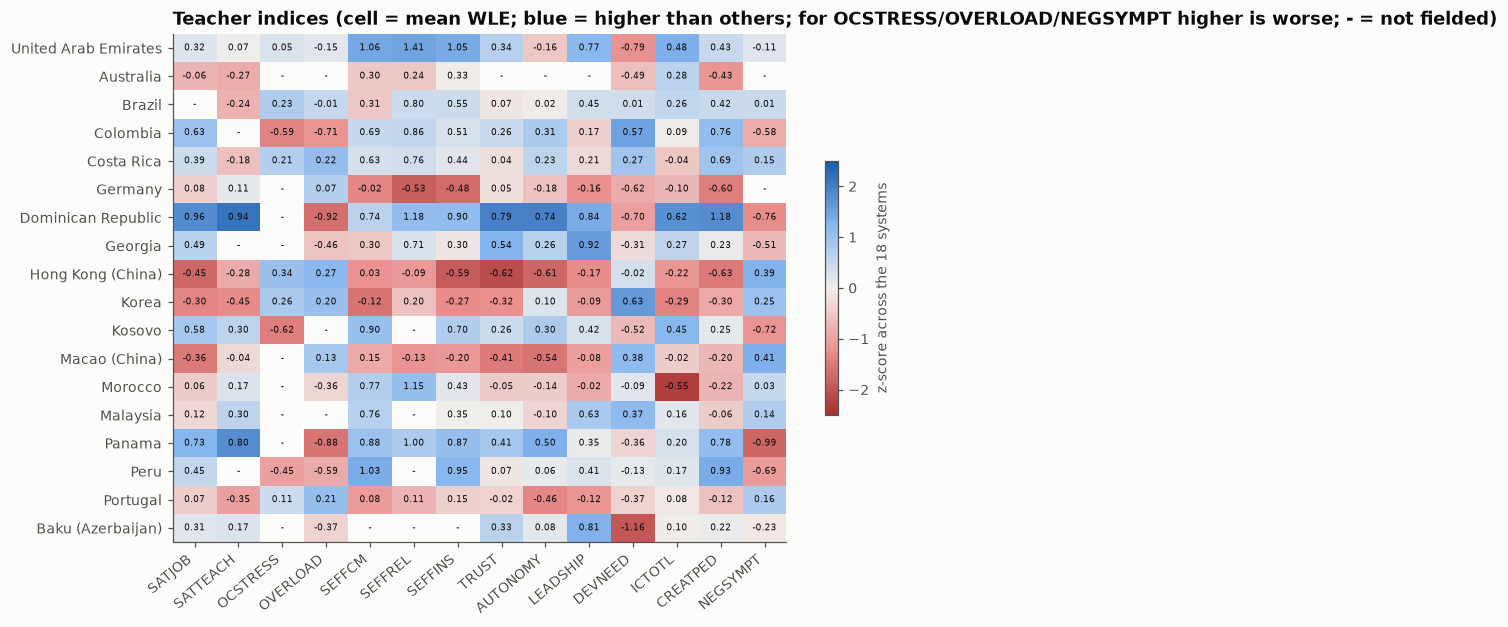

,label
variable,
ICTOTL,Teaching ICT awareness (WLE)
DEVNEED,Need for professional development (WLE)
SATJOB,Satisfaction with current job environment (WLE)
SATTEACH,Satisfaction with teaching profession (WLE)
SEFFCM,Teacher’s self-efficacy in classroom-managemen...
SEFFREL,Teacher’s self-efficacy in maintaining positiv...
SEFFINS,Teacher’s self-efficacy in instructional setti...
CREATPED,Teachers' Use of Creative pedagogies (WLE)
TRUST,Teachers' feeling of trust (WLE)


In [19]:
TV = ['SATJOB','SATTEACH','OCSTRESS','OVERLOAD','SEFFCM','SEFFREL','SEFFINS','TRUST','AUTONOMY','LEADSHIP',
      'DEVNEED','ICTOTL','CREATPED','NEGSYMPT']
tch = load('TCH_QQQ', ['CNT','SENWT'] + TV)
print(f'{len(tch):,} teachers in {tch.CNT.nunique()} systems')
tmean = tch.groupby('CNT').apply(lambda d: pd.Series({v: np.average(d[v].dropna(), weights=d.loc[d[v].notna(), 'SENWT'])
                                                     if d[v].notna().any() else np.nan for v in TV}))
tmean.index = tmean.index.map(NAME)
fig, ax = plt.subplots(figsize=(9, 6))
z = (tmean - tmean.mean()) / tmean.std()
im = ax.imshow(z.to_numpy(), cmap=div.reversed(), norm=TwoSlopeNorm(0, -2.5, 2.5), aspect='auto')
ax.set_xticks(range(len(TV)), TV, rotation=40, ha='right'); ax.set_yticks(range(len(z)), z.index); ax.grid(False)
for (r, c_), v in np.ndenumerate(tmean.to_numpy()):
    ax.text(c_, r, '-' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=6, color=INK)
plt.colorbar(im, ax=ax, shrink=.5, label='z-score across the 18 systems')
ax.set_title('Teacher indices (cell = mean WLE; blue = higher than others; for OCSTRESS/OVERLOAD/NEGSYMPT higher is worse; - = not fielded)', loc='left')
save(fig, '11_teachers')
labels = DD.query('dataset=="teacher" and variable in @TV').set_index('variable').label
display(labels.to_frame())

## 12. Creative Thinking (new domain in 2022, scale 0-60)

The CRT file has no weights, so they are joined from the student file by student ID.

499,843 creative-thinking students with weights, 63 systems


,name,creative,creative_se,gap_girls_minus_boys,gap_girls_minus_boys_se,math
SGP,Singapore,41.00,0.20,2.00,0.40,574.70
KOR,Korea,38.10,0.40,3.10,0.50,527.30
CAN,Canada,37.90,0.20,2.60,0.30,496.90
AUS,Australia,37.30,0.20,2.70,0.30,487.10
NZL,New Zealand,36.40,0.30,3.30,0.50,479.10
EST,Estonia,35.90,0.30,3.40,0.50,509.90
FIN,Finland,35.80,0.30,6.00,0.50,484.10
DNK,Denmark,35.50,0.20,2.70,0.40,489.30
LVA,Latvia,35.10,0.30,2.60,0.40,483.20
BEL,Belgium,34.90,0.30,2.30,0.40,489.50


between-country correlation, creative thinking vs math: 0.87


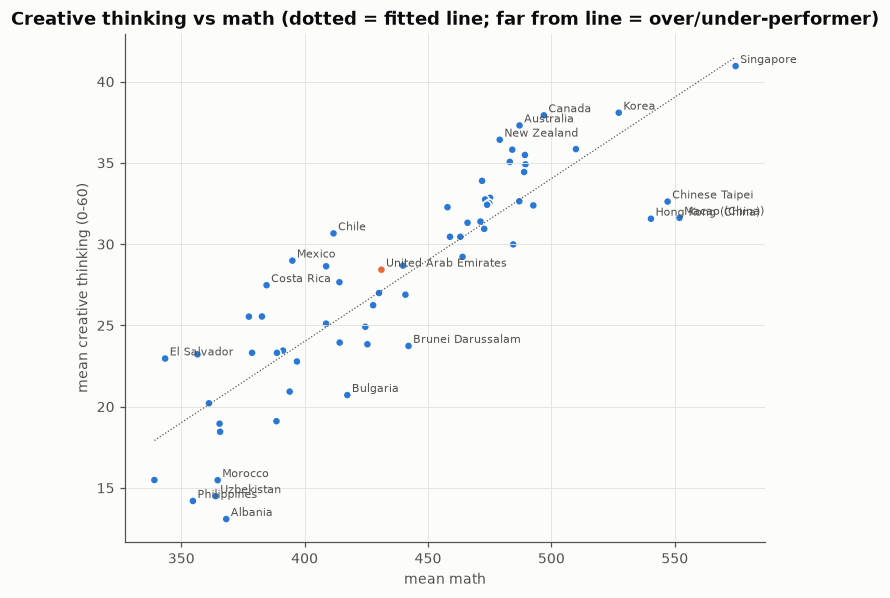

In [20]:
crt = load('CRT_COG', ['CNT','CNTSTUID'] + PV('CRTH_NC')).merge(stu[['CNTSTUID'] + W + PV('MATH') + ['GENDER']],
                                                                  on='CNTSTUID', how='inner')
print(f'{len(crt):,} creative-thinking students with weights, {crt.CNT.nunique()} systems')
creat = table({'creative': mean_of(PV('CRTH_NC')),
               'gap_girls_minus_boys': gap_of(PV('CRTH_NC'), 'GENDER', 'F', 'M')}, df=crt).join(scores[['math']])
creat = creat.dropna(subset=['creative']).sort_values('creative', ascending=False)
display(creat.round(1))
t = creat.drop('OECD')
print('between-country correlation, creative thinking vs math:', round(t.creative.corr(t.math), 2))
fig, ax = plt.subplots(figsize=(7.5, 6))
b, a = np.polyfit(t.math, t.creative, 1)
xs = np.linspace(t.math.min(), t.math.max(), 2); ax.plot(xs, a + b * xs, color=INK2, lw=.8, ls=':')
ax.scatter(t.math, t.creative, s=28, color=[ORANGE if i == FOCUS else BLUE for i in t.index], edgecolor=SURF)
for i in t.index:
    if abs(t.creative[i] - (a + b * t.math[i])) > 4 or i == FOCUS or t.creative[i] > 38:
        ax.annotate(t.name[i], (t.math[i], t.creative[i]), fontsize=7, xytext=(3, 2), textcoords='offset points', color=INK2)
ax.set(xlabel='mean math', ylabel='mean creative thinking (0-60)',
       title='Creative thinking vs math (dotted = fitted line; far from line = over/under-performer)')
save(fig, '12_creative')

## 13. Financial Literacy (separate sample, own weights and PVs)

In [21]:
flt = load('FLT_QQQ', ['CNT','ST004D01T'] + W + PV('FLIT') + PV('MATH') + PV('READ'))
flt['GENDER'] = flt.ST004D01T.map({1: 'F', 2: 'M'})
fin = table({'finlit': mean_of(PV('FLIT')),
             'low_finlit': pct_of(PV('FLIT'), lambda y: y < 400.33),
             'top_finlit': pct_of(PV('FLIT'), lambda y: y >= 624.63),
             'gap_boys_minus_girls': gap_of(PV('FLIT'), 'GENDER', 'M', 'F'),
             'math_same_sample': mean_of(PV('MATH'))}, df=flt)
# OECD average here = only the OECD systems that took part
fin = fin.sort_values('finlit', ascending=False)
display(fin.round(1))
t = fin.drop('OECD')
print('correlation finlit vs math across systems:', round(t.finlit.corr(t.math_same_sample), 2))

,name,finlit,finlit_se,low_finlit,low_finlit_se,top_finlit,top_finlit_se,gap_boys_minus_girls,gap_boys_minus_girls_se,math_same_sample,math_same_sample_se
BEL,Belgium,526.60,3.20,12.00,1.10,16.50,1.00,-5.50,5.00,501.80,2.90
DNK,Denmark,520.50,2.40,10.90,0.80,12.50,0.90,8.80,3.80,488.50,2.20
CAN,Canada,518.70,2.40,12.70,0.60,14.80,0.90,3.80,2.90,492.60,2.10
NLD,Netherlands,516.90,4.40,17.50,1.80,18.50,1.00,3.70,5.00,496.40,3.90
CZE,Czech Republic,506.60,2.20,15.30,0.80,12.50,0.80,6.80,4.30,486.80,2.00
AUT,Austria,506.20,2.80,16.80,0.90,13.20,0.80,7.90,3.70,486.40,2.40
POL,Poland,505.80,2.70,14.80,1.00,9.90,0.80,0.50,4.20,487.10,2.70
USA,United States,505.20,4.90,16.80,1.40,13.50,1.20,8.20,4.70,465.50,4.60
OECD,OECD average,497.90,0.80,17.90,0.30,10.60,0.20,5.40,1.10,474.30,0.80
PRT,Portugal,494.40,2.40,15.50,1.10,6.60,0.60,8.00,3.20,469.30,2.30


correlation finlit vs math across systems: 0.97


## 14. Cognitive items: what students got right and how long it took

785 scored items, 605 timing vars


timing unit inferred: milliseconds | sampled students: 42749


,items,median_pct_correct,median_seconds
domain,,,
math,243,43.20,65.20
reading,376,77.50,27.00
science,166,45.10,52.40



hardest items:


,domain,label,pct_correct,median_seconds,administered
CM943Q02S,math,Arches - Q02,3.80,75.90,"52,103.00"
PR432Q06S,reading,About a book - Q06 (Paper Scored Response),4.40,NaN,990.00
CM955Q03S,math,Migration - Q03,5.20,69.20,"63,738.00"
PM192Q01AS,math,Mathematics: Containers - Q01 (Paper Scored Re...,5.40,NaN,"3,419.00"
PR466Q03S,reading,Work Right - Q03 (Paper Scored Response),5.70,NaN,"1,048.00"
CM00GQ01S,math,Advertising Column - Q01,6.80,121.40,"61,562.00"
PM967Q03S,math,Wooden Train Set - Q03 (Paper Scored Response),7.00,NaN,"1,822.00"
PS527Q01S,science,Extinction of the Dinosaurs - Q01 (Paper Score...,7.90,NaN,"1,068.00"


easiest items:


,domain,label,pct_correct,median_seconds,administered
PR922P25AS,reading,Reading Components: PC P1 S4 Health Clinic,98.50,NaN,"2,373.00"
PR921P08AS,reading,Reading Components: PC P2 S3 Birthday Party,98.00,NaN,"2,362.00"
PR921P11AS,reading,Reading Components: PC P2 S6 Birthday Party,98.00,NaN,"2,355.00"
PR921P02AS,reading,Reading Components: PC P1 S2 Birthday Party,97.70,NaN,"2,367.00"
PR921P12AS,reading,Reading Components: PC P2 S7 Birthday Party,97.50,NaN,"2,326.00"
PR921P43AS,reading,Reading Components: PC P2 S1 World Sports,97.50,NaN,"2,285.00"
PR921P05AS,reading,Reading Components: PC P1 S5 Birthday Party,97.30,NaN,"2,364.00"
PR922P24AS,reading,Reading Components: PC P1 S3 Health Clinic,97.20,NaN,"2,378.00"


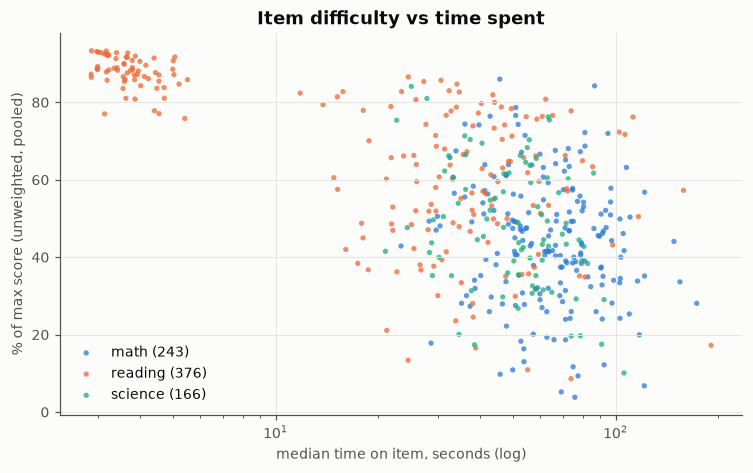

In [22]:
cog_cols = cols('STU_COG')
lab = DD[DD.dataset == 'cognitive'].set_index('variable').label
scored = [c for c in cog_cols if isinstance(lab.get(c), str) and 'Scored Response' in lab[c]]
timing = [c for c in cog_cols if isinstance(lab.get(c), str) and 'Total Timing' in lab[c]]
print(len(scored), 'scored items,', len(timing), 'timing vars')

n = pd.Series(0.0, index=scored); tot = pd.Series(0.0, index=scored); mx = pd.Series(0.0, index=scored)
tsamp = []
for i, batch in enumerate(batches('STU_COG', scored + timing)):
    b = batch.to_pandas()
    S = b[scored]
    n += S.notna().sum(); tot += S.sum(); mx = np.maximum(mx, S.max().fillna(0))
    if i % 3 == 0: tsamp.append(b[timing].sample(frac=.2, random_state=i))
items = pd.DataFrame({'administered': n, 'mean_score': tot / n, 'max_score': mx})
items['pct_correct'] = 100 * items.mean_score / items.max_score
items['domain'] = items.index.str[1].map({'M': 'math', 'R': 'reading', 'S': 'science'}).fillna('other')
items['label'] = lab.reindex(items.index).str.replace(r' \(Scored Response\)', '', regex=True)
T = pd.concat(tsamp)
# timing unit check: SPSS labels do not state it, so infer from the median of all items
med = T.median()
unit = 1000 if med.median() > 1000 else 1
items['median_seconds'] = (med / unit).rename(lambda c: c[:-2] + 'S').reindex(items.index)
print('timing unit inferred:', 'milliseconds' if unit == 1000 else 'seconds', '| sampled students:', len(T))
display(items.groupby('domain').agg(items=('label','size'), median_pct_correct=('pct_correct','median'),
                                    median_seconds=('median_seconds','median')).round(1))
print('\nhardest items:'); display(items.nsmallest(8, 'pct_correct')[['domain','label','pct_correct','median_seconds','administered']].round(1))
print('easiest items:'); display(items.nlargest(8, 'pct_correct')[['domain','label','pct_correct','median_seconds','administered']].round(1))
items.to_csv(OUT/'item_statistics.csv')

fig, ax = plt.subplots(figsize=(8, 4.5))
for dom, col in [('math', BLUE), ('reading', ORANGE), ('science', AQUA)]:
    d = items[items.domain == dom]
    ax.scatter(d.median_seconds, d.pct_correct, s=12, color=col, alpha=.75, label=f'{dom} ({len(d)})', edgecolor='none')
ax.set_xscale('log'); ax.legend(frameon=False)
ax.set(xlabel='median time on item, seconds (log)', ylabel='% of max score (unweighted, pooled)',
       title='Item difficulty vs time spent')
save(fig, '14_items')

In [23]:
# test effort (1-10 scale, asked right after the test) vs performance
eff = table({'effort': mean_of(['EFFORT1']), 'effort_if_counted': mean_of(['EFFORT2'])}).join(scores[['math']])
t = eff.drop('OECD')
print('between-country correlation effort vs math:', round(t.effort.corr(t.math), 2))
print('within-country: OECD avg math points per effort point:',
      round(with_oecd(estimate(stu, slope_of('EFFORT1', PV('MATH')))).loc['OECD', 'est'], 1))
display(eff.sort_values('effort').round(2).head(10))

between-country correlation effort vs math: -0.63


within-country: OECD avg math points per effort point: 6.2


,name,effort,effort_se,effort_if_counted,effort_if_counted_se,math
NOR,Norway,6.91,0.03,9.03,0.03,468.45
JPN,Japan,6.99,0.04,8.52,0.03,535.58
MLT,Malta,7.03,0.04,8.87,0.04,466.02
DEU,Germany,7.04,0.03,9.02,0.02,474.83
FRA,France,7.04,0.03,8.81,0.02,473.94
BEL,Belgium,7.08,0.03,8.86,0.02,489.49
AUT,Austria,7.10,0.04,8.93,0.03,487.27
ISL,Iceland,7.15,0.04,8.85,0.03,458.91
GRC,Greece,7.16,0.04,8.82,0.03,430.15
SWE,Sweden,7.17,0.04,9.32,0.02,481.77


## 15. Questionnaire timing file

In [24]:
tim = load('STU_TIM', ['CNT','CNTSTUID'] + [c for c in cols('STU_TIM') if c.endswith('_TT')])
tt = [c for c in tim if c.endswith('_TT')]
unit = 1000 if tim[tt].median().median() > 1000 else 1
tim['total_min'] = tim[tt].sum(axis=1, min_count=1) / unit / 60
print('timing unit inferred:', 'ms' if unit == 1000 else 's')
tq = tim.groupby('CNT').total_min.median().rename('median_questionnaire_minutes').to_frame()
tq['name'] = tq.index.map(NAME)
display(tq.sort_values('median_questionnaire_minutes').round(1).T)
slow = (tim[tt].median() / unit).sort_values(ascending=False).head(10).rename('median_seconds').to_frame()
slow['question'] = DD[DD.dataset == 'timing'].set_index('variable').label.reindex(slow.index)
print('slowest questionnaire screens (median seconds):'); display(slow.round(1))

timing unit inferred: ms


CNT,QAZ,ALB,KSV,MNE,QAT,SGP,ISR,KOR,CAN,NOR,JPN,TAP,JOR,SRB,PSE,MKD,AUS,SWE,NZL,GBR,...,DEU,IRL,DNK,AUT,BRN,ITA,SAU,CZE,MAR,BRA,PER,PAN,MYS,HUN,ESP,CRI,GTM,KHM,PRY,VNM
median_questionnaire_minutes,24.50,26.60,28.60,28.60,29.40,30.00,30.50,30.60,31.30,31.50,32.30,32.70,32.90,33.40,33.80,34.40,34.40,34.90,35.40,35.70,...,45.30,46.50,46.90,47.30,47.40,48.80,49.40,49.70,50.00,51.70,52.00,53.30,54.80,55.20,56.60,57.30,NaN,NaN,NaN,NaN
name,Baku (Azerbaijan),Albania,Kosovo,Montenegro,Qatar,Singapore,Israel,Korea,Canada,Norway,Japan,Chinese Taipei,Jordan,Serbia,Palestinian Authority,North Macedonia,Australia,Sweden,New Zealand,United Kingdom,...,Germany,Ireland,Denmark,Austria,Brunei Darussalam,Italy,Saudi Arabia,Czech Republic,Morocco,Brazil,Peru,Panama,Malaysia,Hungary,Spain,Costa Rica,Guatemala,Cambodia,Paraguay,Viet Nam


slowest questionnaire screens (median seconds):


,median_seconds,question
ST014_TT,52.10,Total Time: ST014
ST326_TT,49.00,Total Time: ST326
FL171_TT,47.90,Total Time: FL171
ST322_TT,45.30,Total Time: ST322
ST038_TT,41.20,Total Time: ST038
ST251_TT,39.80,Total Time: ST251
ST267_TT,38.20,Total Time: ST267
FL164_TT,37.90,Total Time: FL164
FL169_TT,36.40,Total Time: FL169
ST261_TT,36.30,Total Time: ST261


## 16. ESCS over time (trend file, 2012-2022)

year,name,2012,2015,2018,2022,change_2012_2022
cnt,,,,,,
FIN,Finland,0.27,0.22,0.29,0.19,-0.07
JOR,Jordan,-0.75,-0.70,-0.76,-0.80,-0.05
ISL,Iceland,0.40,0.44,0.46,0.38,-0.02
DEU,Germany,-0.11,-0.14,-0.13,-0.12,-0.01
SWE,Sweden,0.29,0.28,0.31,0.33,0.05
FRA,France,-0.11,-0.09,-0.15,-0.06,0.05
QAT,Qatar,0.02,0.18,0.20,0.11,0.09
BEL,Belgium,-0.02,0.01,0.02,0.12,0.13
GBR,United Kingdom,-0.03,0.07,0.11,0.12,0.15


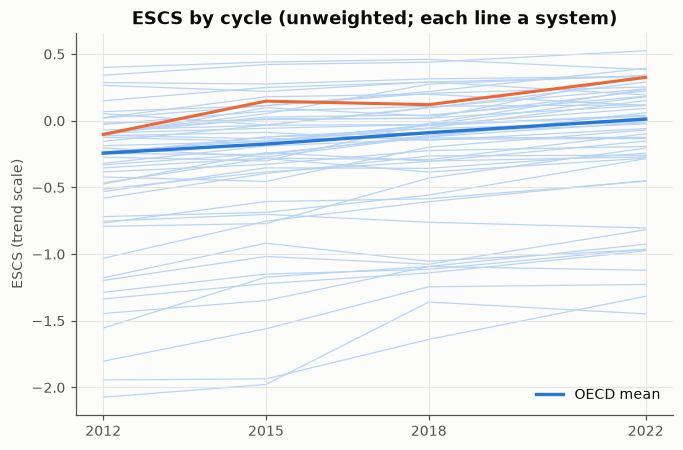

In [25]:
et = pd.read_parquet(PQ/'escs_trend')
et['year'] = et.cycle.map({5: 2012, 6: 2015, 7: 2018})
e22 = stu[['CNT','OECD','ESCS']].rename(columns={'ESCS': 'escs_trend', 'OECD': 'oecd', 'CNT': 'cnt'}).assign(year=2022)
allc = pd.concat([et[['cnt','oecd','year','escs_trend']], e22])
# the trend file carries no weights, so these are unweighted sample means (fine for direction, not for exact levels)
tr = allc.groupby(['cnt','year']).escs_trend.mean().unstack()
tr = tr[tr.notna().sum(axis=1) == 4]
tr['change_2012_2022'] = tr[2022] - tr[2012]
tr.insert(0, 'name', tr.index.map(NAME))
display(tr.sort_values('change_2012_2022').round(2))
fig, ax = plt.subplots(figsize=(7, 4.5))
for c in tr.index:
    ax.plot([2012, 2015, 2018, 2022], tr.loc[c, [2012, 2015, 2018, 2022]].astype(float),
            color=ORANGE if c == FOCUS else '#b7d3f6', lw=2 if c == FOCUS else .8, zorder=3 if c == FOCUS else 1)
oe = tr.loc[tr.index.isin(OECD), [2012, 2015, 2018, 2022]].mean()
ax.plot(oe.index, oe.values, color=BLUE, lw=2.2, label='OECD mean'); ax.legend(frameon=False)
ax.set(title='ESCS by cycle (unweighted; each line a system)', ylabel='ESCS (trend scale)'); ax.set_xticks([2012, 2015, 2018, 2022])
save(fig, '16_escs_trend')

## 17. Country profile: everything above for `FOCUS`

In [26]:
panel = (scores[['name','math','read','sci']]
         .join(prof[['low_MATH','top_MATH','low_READ','low_SCIE']])
         .join(gg[['gap_MATH','gap_READ']])
         .join(eq[['escs_mean','gradient','pct_var']])
         .join(dist[['pct_distracted_own']])
         .join(cov19[['closed_gt3m','learnt_less']])
         .join(schools[['pct_private','private_minus_public','between_school_pct']])
         .join(creat[['creative']]).join(fin[['finlit']]).join(eff[['effort']]))
panel.to_csv(OUT/'country_summary.csv')
countries = panel.drop('OECD')
rank = countries.drop(columns='name').rank(ascending=False, method='min').astype('Int64')
prof_f = pd.DataFrame({FOCUS: panel.loc[FOCUS].drop('name'), 'OECD avg': panel.loc['OECD'].drop('name'),
                       'rank (1 = highest)': rank.loc[FOCUS], 'systems with data': countries.drop(columns='name').count(),
                       'min': countries.drop(columns='name').min(), 'max': countries.drop(columns='name').max()})
print(NAME.get(FOCUS, FOCUS)); display(prof_f.round(1))
print(f'country_summary.csv written: {panel.shape}')

United Arab Emirates


,ARE,OECD avg,rank (1 = highest),systems with data,min,max
math,431.11,472.36,43,80,336.40,574.70
read,417.35,475.59,48,80,328.80,542.60
sci,431.98,484.65,47,80,347.10,561.40
low_MATH,49.00,31.09,36,80,8.00,92.40
top_MATH,5.33,8.70,39,80,0.00,40.50
low_READ,48.00,26.25,31,80,11.20,92.10
low_SCIE,45.05,24.49,33,80,7.40,89.60
gap_MATH,-7.09,9.05,72,80,-19.10,21.10
gap_READ,-44.55,-24.21,77,80,-49.40,-2.60
escs_mean,0.30,0.00,9,79,-2.00,0.50


country_summary.csv written: (81, 22)


## 18. Key findings (computed from the cells above)

In [27]:
o, c = scores.loc['OECD'], scores.drop('OECD')
top5 = ', '.join(f'{c.name[i]} {c.math[i]:.0f}' for i in c.math.nlargest(5).index)
bot3 = ', '.join(f'{c.name[i]} {c.math[i]:.0f}' for i in c.math.nsmallest(3).index)
lp = prof.drop('OECD')
F = [
 f"Coverage: {len(stu):,} students, {stu.CNT.nunique()} systems, representing ~{stu.W_FSTUWT.sum()/1e6:.1f}M 15-year-olds.",
 f"OECD averages: math {o.math:.0f}, reading {o.read:.0f}, science {o.sci:.0f} (reproduces the published figures).",
 f"Top in math: {top5}. Bottom: {bot3}. Spread top-to-bottom ~{c.math.max()-c.math.min():.0f} points.",
 f"{prof.loc['OECD','low_MATH']:.0f}% of students in the average OECD country are below math Level 2; "
 f"in {int((lp.low_MATH > 50).sum())} systems it is over half.",
 f"Gender: girls ahead in reading by {-gg.loc['OECD','gap_READ']:.0f} points on OECD average; boys ahead in math by "
 f"{gg.loc['OECD','gap_MATH']:.0f}.",
 f"Equity: ESCS explains {eq.loc['OECD','pct_var']:.0f}% of math variance on OECD average; top vs bottom ESCS quarter gap "
 f"{eq.loc['OECD','q4_minus_q1']:.0f} points.",
 f"Strongest positive within-country association: {assoc.label.iloc[-1]} ({assoc.per_SD.iloc[-1]:+.0f}/SD); "
 f"strongest negative: {assoc.label.iloc[0]} ({assoc.per_SD.iloc[0]:+.0f}/SD).",
 f"Phones: {dist.loc['OECD','pct_distracted_own']:.0f}% of OECD students are distracted by digital devices in most/every math lesson; "
 f"those distracted every lesson score {by_freq['never/almost never']-by_freq['every lesson']:.0f} points below those who never are.",
 f"COVID: {cov19.loc['OECD','closed_gt3m']:.0f}% of OECD students had schools closed >3 months; "
 f"{cov19.loc['OECD','learnt_less']:.0f}% say they learnt less.",
 f"Schools: on OECD average {schools.loc['OECD','between_school_pct']:.0f}% of math variance lies between schools; "
 f"private-public gap {schools.loc['OECD','private_minus_public']:+.0f} raw vs {schools.loc['OECD','private_gap_adjusted']:+.0f} after ESCS.",
 f"Creative thinking tracks math closely across countries (r = {creat.drop('OECD').creative.corr(creat.drop('OECD').math):.2f}).",
]
for f in F: print('-', f)
(OUT/'key_findings.md').write_text('# PISA 2022: key findings\n\n' + '\n'.join('- ' + f for f in F) + '\n')

- Coverage: 613,744 students, 80 systems, representing ~28.3M 15-year-olds.
- OECD averages: math 472, reading 476, science 485 (reproduces the published figures).
- Top in math: Singapore 575, Macao (China) 552, Chinese Taipei 547, Hong Kong (China) 540, Japan 536. Bottom: Cambodia 336, Paraguay 338, Dominican Republic 339. Spread top-to-bottom ~238 points.
- 31% of students in the average OECD country are below math Level 2; in 34 systems it is over half.
- Gender: girls ahead in reading by 24 points on OECD average; boys ahead in math by 9.
- Equity: ESCS explains 15% of math variance on OECD average; top vs bottom ESCS quarter gap 93 points.
- Strongest positive within-country association: Index of economic, social and cultural status (+45/SD); strongest negative: Mathematics Anxiety (WLE) (-23/SD).
- Phones: 30% of OECD students are distracted by digital devices in most/every math lesson; those distracted every lesson score 29 points below those who never are.
- COVID: 51% of OECD

1277